# 02 - Time-series exploration 

Section 5.2 of the project: timestamp quality, autocorrelation, stationarity, drift and lead-lag. This is the 'decision gate' to know if temporal validation and lag features make sense.

In [1]:
import sys, os
sys.path.append(os.path.join('..', 'src'))
import pandas as pd
from IPython.display import Image, display
import config
from data_loader import load_and_clean_data
pd.set_option('display.max_rows', 100)
from eda import save_exploratory_temporal

df, log = load_and_clean_data()
save_exploratory_temporal(df)
temp = pd.read_csv(os.path.join(config.RESULTS_DIR, 'Exploratory_temporal.csv'))

1. Loading data...


   Original shape: (41718, 15)
   Date range: 2016-11-25 -> 2026-04-06
   Stations: 94 names, 98 ids
   Latitude: 36.13 to 43.53, Longitude: -5.66 to 9.14
   Duplicates removed: 0 full rows, 2 on (date, station)
   Removed bad pm25 rows: 735 (missing: 0, <=0: 727, >=500: 8)
   Cleaning done. New shape: (40981, 15)



## 1. Timestamp quality
Only about 2/3 of the records come exactly 1 day after the previous record of the same station. So we must not compute lags with a simple shift: in `features.py` a lag is set to NaN when yesterday is missing.

In [2]:
temp[temp.section == 'timestamps']

,section,variable,metric,value
0,timestamps,all,days_in_full_range,3420
1,timestamps,all,days_with_data,2299
2,timestamps,all,days_missing_all_stations,1121
3,timestamps,all,duplicate_station_dates,0
4,timestamps,all,pct_consecutive_1day,66.66
5,timestamps,all,n_gaps_over_1day,13631
6,timestamps,all,median_gap_days,1.0
7,timestamps,all,max_gap_days,2383.0
8,timestamps,all,station_coverage_pct_median,50.06
9,timestamps,all,stations_under_100_records,15


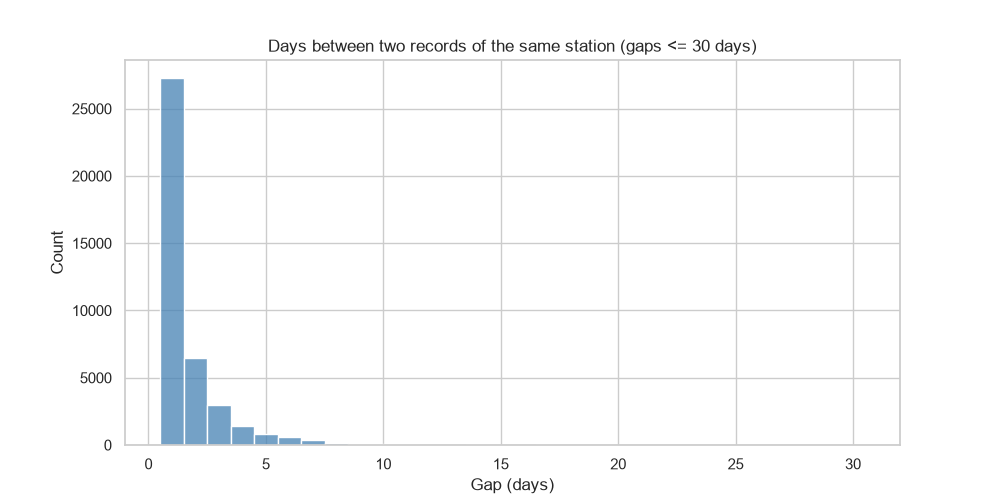

In [3]:
display(Image(os.path.join(config.FIGURES_DIR, 'timestamp_gaps.png')))

## 2. Autocorrelation (ACF / PACF)
The ACF decreases slowly and the PACF has one big spike at lag 1. So yesterday's PM2.5 is the most useful past value, which justifies the lag-1 and 7-day rolling features.

In [4]:
temp[temp.section.isin(['acf_station_mean', 'acf_regional', 'pacf_regional'])].pivot(index='metric', columns='section', values='value')

section,acf_regional,acf_station_mean,pacf_regional
metric,,,
lag_1,0.5811,0.3817,0.5819
lag_10,0.0753,0.0846,0.0232
lag_11,0.0697,0.0856,0.014
lag_12,0.071,0.0882,0.0163
lag_13,0.0802,0.0886,0.0342
lag_14,0.0916,0.0765,0.029
lag_2,0.3852,0.2372,0.072
lag_3,0.3034,0.1844,0.0822
lag_4,0.2312,0.1548,0.0172


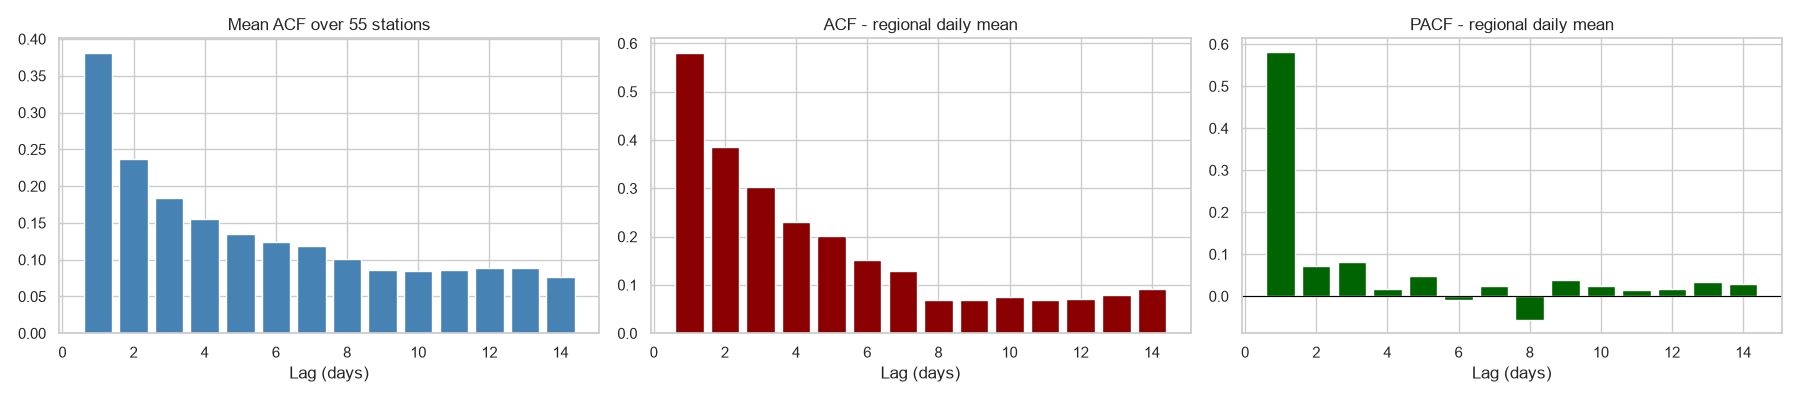

In [5]:
display(Image(os.path.join(config.FIGURES_DIR, 'acf_pacf.png')))

## 3. Stationarity (ADF) and Ljung-Box

In [6]:
temp[temp.section.isin(['regional_series', 'adf_test', 'ljung_box'])]

,section,variable,metric,value
25,regional_series,pm25,n_days_used,819
26,regional_series,pm25,start_date,2023-03-30
27,regional_series,pm25,end_date,2025-06-25
28,regional_series,pm25,n_days_interpolated,25
57,adf_test,pm25,adf_statistic,-10.2644
58,adf_test,pm25,p_value,4.154855070037459e-18
59,adf_test,pm25,stationary_at_5pct,True
60,ljung_box,pm25,p_value_lag_7,2.277243731881691e-122
61,ljung_box,pm25,p_value_lag_14,3.939658487307691e-123


ADF p-value < 0.05, so the regional series is stationary (no strong trend). Ljung-Box p-values are ~0, so the values are not independent from one day to the next: this is why we need temporal CV and not only random CV.

## 4. Drift over years and months

In [7]:
temp[temp.section == 'drift_year'].pivot(index='variable', columns='metric', values='value')

metric,iqr,median,n_records,pct_above_25,pct_above_50
variable,,,,,
2016,7.056,10.167,111,1.8,0.0
2017,7.297,7.667,2116,3.83,0.33
2018,6.172,7.019,252,0.4,0.0
2019,9.387,6.718,1772,4.29,0.06
2020,6.56,5.714,3247,2.06,0.09
2021,7.427,6.8,4746,2.38,0.59
2022,7.365,8.125,4954,2.02,0.46
2023,7.434,9.0,5400,2.44,0.2
2024,6.931,8.0,8686,3.15,0.21


In [8]:
temp[temp.section == 'drift_month'].pivot(index='variable', columns='metric', values='value')

metric,iqr,median,n_records,pct_above_25,pct_above_50
variable,,,,,
1,8.898,8.145,3032,4.85,0.4
10,7.143,7.8,3043,2.46,0.1
11,8.111,7.908,3369,3.59,0.5
12,9.603,8.907,2793,7.05,0.39
2,9.391,9.25,3113,6.62,0.55
3,7.58,7.257,2752,4.0,0.62
4,5.866,6.439,2998,1.3,0.27
5,5.723,6.873,3526,0.82,0.23
6,7.094,7.812,4154,1.9,0.05


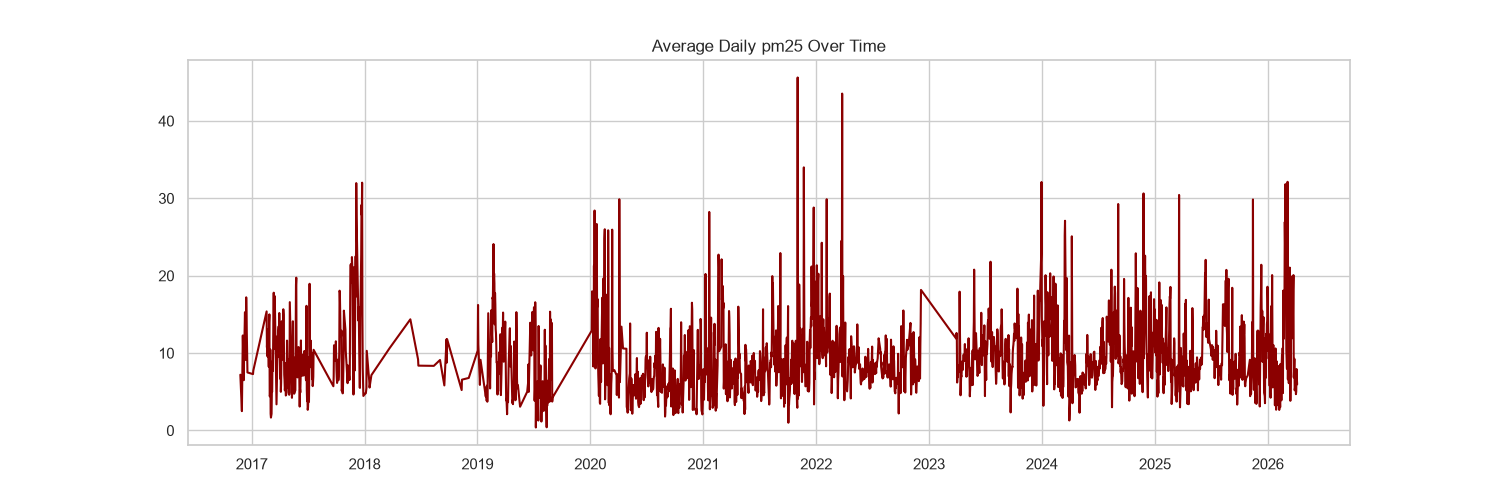

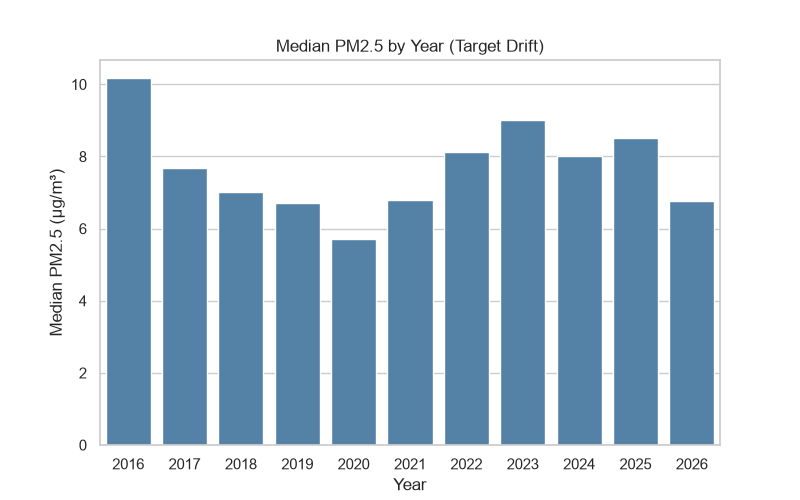

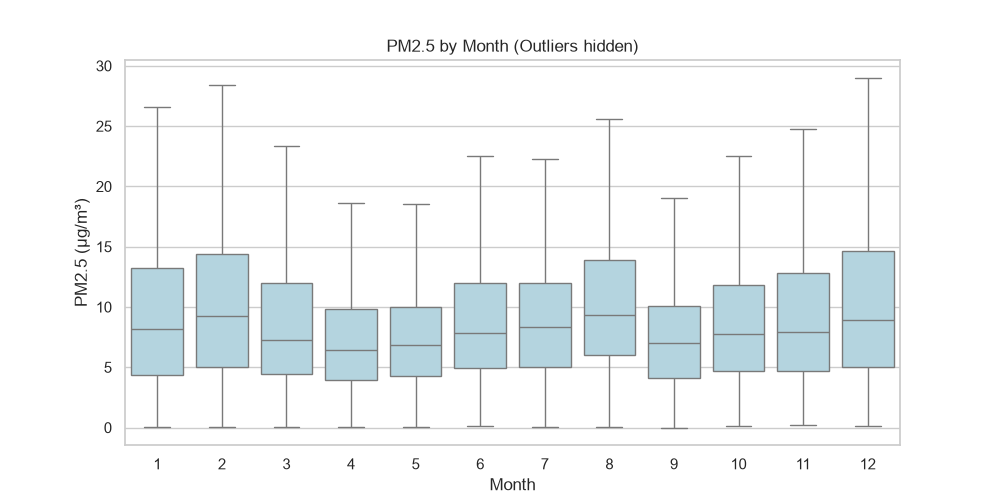

In [9]:
display(Image(os.path.join(config.FIGURES_DIR, 'time_series.png')))
display(Image(os.path.join(config.FIGURES_DIR, 'drift_by_year.png')))
display(Image(os.path.join(config.FIGURES_DIR, 'pm25_by_month.png')))

Monthly pattern of the atmospheric predictors. AOD is highest in summer. For PM2.5 the highest monthly median is in August (9.4), but winter has the most polluted days (7.1% of days above 25 ug/m3 in December, 6.6% in February).

In [10]:
temp[temp.section == 'predictor_by_month'].pivot(index='metric', columns='variable', values='value').astype(float).round(5)

variable,AOD,CO,NO2,O3,pressure_mb,temperature_celsius,wind_u,wind_v
metric,,,,,,,,
month_1,0.07150,0.03169,0.00008,0.14886,1002.21449,10.02591,1.19075,-0.59907
month_10,0.13150,0.02969,0.00008,0.12898,999.57698,19.02180,0.08236,-0.04421
month_11,0.08950,0.02999,0.00008,0.13079,1000.01860,14.20587,0.84631,-0.61193
month_12,0.08000,0.03123,0.00008,0.13759,1002.71652,10.85055,0.83184,-0.68145
month_2,0.09000,0.03271,0.00009,0.14652,1001.96774,11.75581,0.65505,-0.31112
month_3,0.12275,0.03389,0.00008,0.15547,997.70919,12.26714,0.50311,-0.20553
month_4,0.13200,0.03397,0.00009,0.15682,996.92244,15.33821,0.24269,0.10485
month_5,0.14700,0.03253,0.00009,0.15530,996.60262,19.13522,-0.12414,0.28936
month_6,0.16700,0.03024,0.00009,0.14467,995.63216,23.25118,-0.43626,0.43193


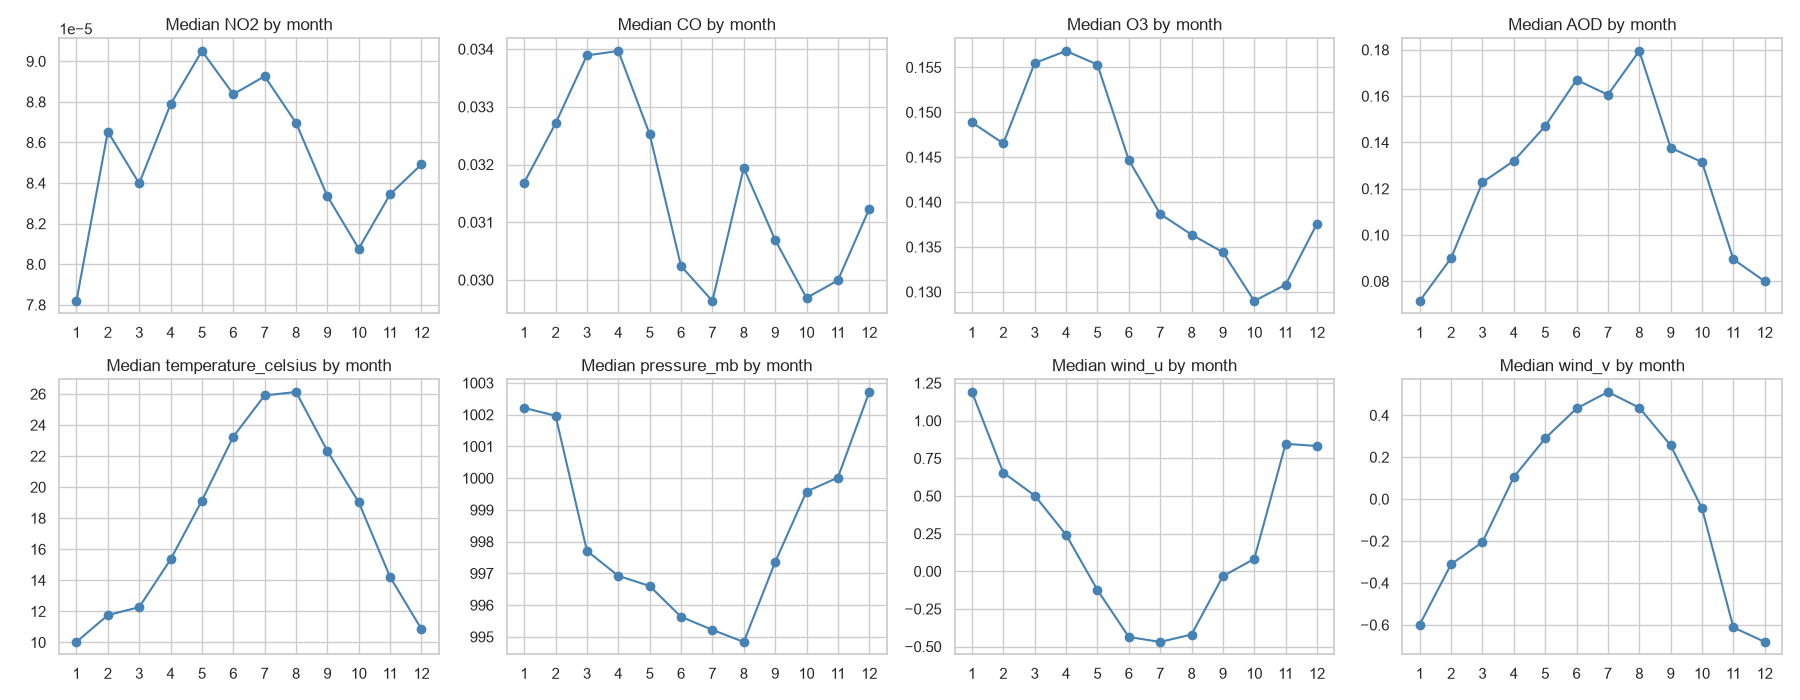

In [11]:
display(Image(os.path.join(config.FIGURES_DIR, 'predictors_by_month.png')))

## 5. Lead-lag relationships
Correlation between PM2.5 at day t and each predictor at day t-lag (same station, real dates).

In [12]:
temp[temp.section == 'lead_lag_spearman'].pivot(index='variable', columns='metric', values='value')

metric,lag_0,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,lag_7
variable,,,,,,,,
AOD,0.1801,0.1181,0.0719,0.0667,0.0313,0.0178,0.0185,0.0059
CO,0.0363,0.0519,0.055,0.0685,0.0559,0.0352,0.0315,0.0348
NO2,0.2468,0.2408,0.1834,0.1525,0.1259,0.1201,0.1161,0.1055
O3,-0.1351,-0.137,-0.1017,-0.0722,-0.0647,-0.0652,-0.0784,-0.058
pressure_mb,0.1671,0.1809,0.1866,0.1759,0.1581,0.1573,0.1471,0.1381
temperature_celsius,0.0641,0.0586,0.0438,0.0412,0.0354,0.039,0.0432,0.033
wind_u,-0.1635,-0.1625,-0.1372,-0.1158,-0.075,-0.06,-0.0442,-0.0345
wind_v,0.0972,0.0746,0.0211,-0.0036,-0.0087,0.0095,0.0063,-0.007


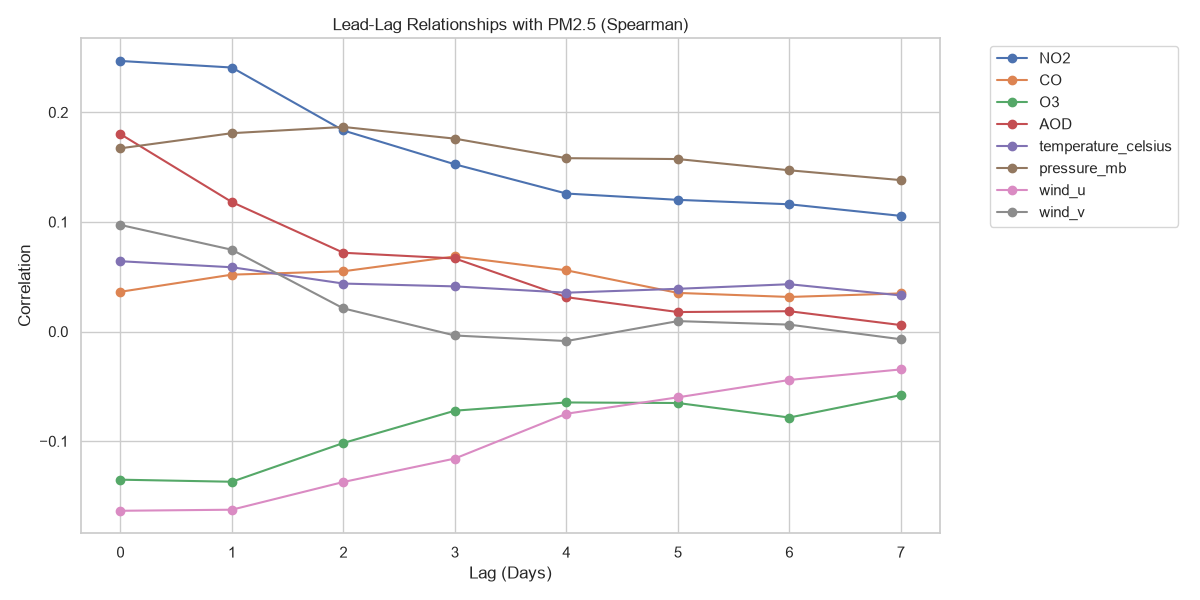

In [13]:
display(Image(os.path.join(config.FIGURES_DIR, 'lead_lag_plot.png')))

## 6. Decision gate
- Timestamps are reliable (no duplicate station-date after cleaning), but there are many gaps.
- PM2.5 is autocorrelated (ACF lag 1 about 0.6 regional, 0.4 per station), so lag and rolling features are justified, as long as they use past days only and are not computed across gaps.
- So we use temporal CV (TimeSeriesSplit, 1-day gap) as the main scheme, and keep random CV only as a diagnostic.